# Chapter 10: Lasso Regression

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.mlab as mlab
import seaborn as sns; sns.set()
from scipy import stats
import math
import os
import random
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import Lasso

## 10.1 Introduction & Motivation

We've learned a lot about building models for regression, classification, and clustering so far! But what if we could not only build great models but also take a closer look at the data itself and figure out which parts really matter? That’s where **Lasso Regression** comes in.

Lasso is more than just another regression model. It helps us uncover which features in our data are truly important by shrinking some coefficients to zero, effectively selecting the key players. Whether we’re predicting prices or classifying categories, Lasso cuts through the noise and keeps only what counts.

## 10.2 Problem Setting

Imagine you’re a wildlife detective, tasked with uncovering the hidden age of possums caught in the wild. With nothing but a handful of measurements—like head length, tail length, and skull size—you’re on a mission to crack the code of their age.

Why does this matter? Knowing a possum’s age can reveal fascinating stories about its life: how it grows, how long it survives, and what’s happening in its environment. By analyzing this data, you’ll uncover patterns that not only help us understand these curious creatures but also contribute to their conservation. 

The dataset contains 10 columns, where 'age' is the value you will try to predict.

- 'case': observation number
- 'site': The site number where the possum was trapped.
- 'Pop': Population, either Vic (Victoria) or other (New South Wales or Queensland).
- 'sex': Gender, either m (male) or f (female).
- 'age': Age.
- 'hdlngth': Head length, in mm.
- 'skullw': Skull width, in mm.
- 'totlngth': Total length, in cm.
- 'taill': Tail length, in cm.
- 'footlgth': foot length

## 10.3 Model

As always, we start by exploring the data.

In [2]:
rdf = pd.read_csv("Possum.csv")
rdf = rdf.drop("Pop", axis=1)
rdf["sex"] = pd.get_dummies(rdf["sex"], drop_first=True, dtype=int)
rdf.head()

,case,site,sex,age,hdlngth,skullw,totlngth,taill,footlgth,earconch,eye,chest,belly
0,1,1,1,8.0,94.1,60.4,89.0,36.0,74.5,54.5,15.2,28.0,36.0
1,2,1,0,6.0,92.5,57.6,91.5,36.5,72.5,51.2,16.0,28.5,33.0
2,3,1,0,6.0,94.0,60.0,95.5,39.0,75.4,51.9,15.5,30.0,34.0
3,4,1,0,6.0,93.2,57.1,92.0,38.0,76.1,52.2,15.2,28.0,34.0
4,5,1,0,2.0,91.5,56.3,85.5,36.0,71.0,53.2,15.1,28.5,33.0


#### Question 1: Create a correlation matrix for the possum dataset. If you run into errors, solve them in a way we have seen before!

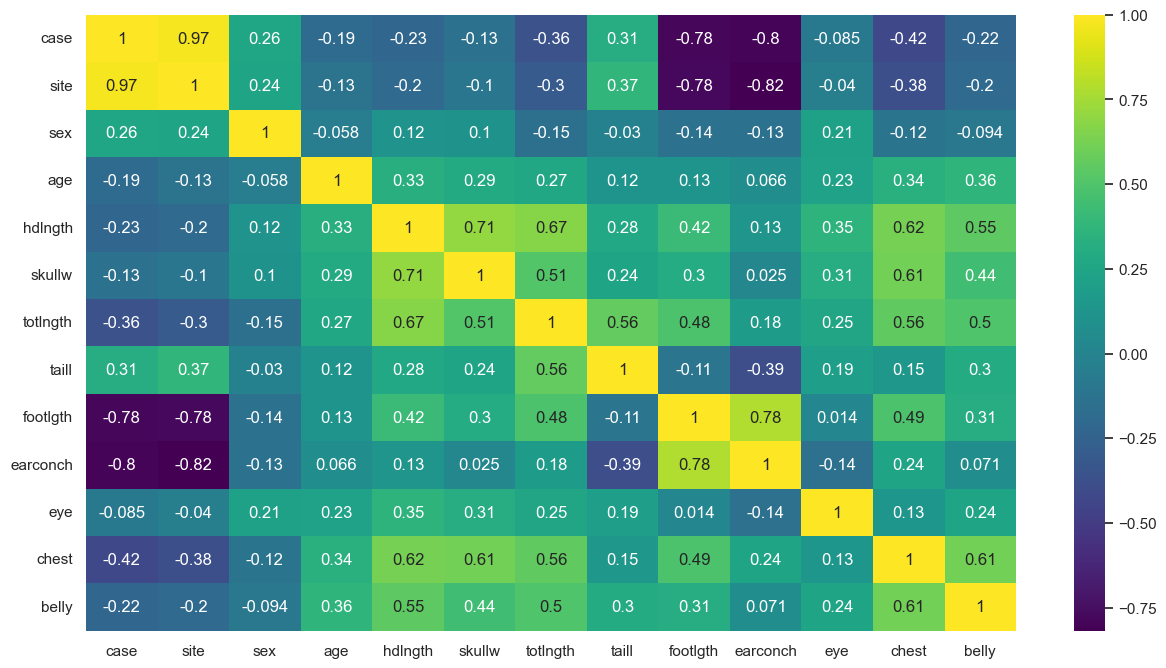

In [3]:
plt.figure(figsize=(15,8))

sns.heatmap(rdf.corr(), cmap="viridis", annot=True)
plt.show()

#### Question 2: Looking at the correlation matrix, which features do you expect to contribute a lot to the 'age' variable? Which features contribute next to nothing?

#### Usefull features
- Belly
- Chest
- Hdlngth
- Skullw
- Totlngth
- Eye

#### Not Usefull features
- Sex
- Earconch
- Site
- Tail

#### Question 3: Train a polynomial regression model using all available features. Figure out the best degree to use. What's the MSE value you get?

In [15]:
X = rdf.drop("age", axis=1)
y = rdf["age"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)

polymodel = LinearRegression()

pol_0 = PolynomialFeatures(degree=4)
polymodel.fit(pol_0.fit_transform(X_train), y_train)

y_predictions = polymodel.predict(pol_0.transform(X_test))

mse = mean_squared_error(y_test, y_predictions)

print(mse)

24.740673943114984


In [5]:
train_MSE = []
test_MSE = []
    

for i in range(0, 10):
    print("DEGREE:", i)
    pol_0 = PolynomialFeatures(degree=i)
    polymodel.fit(pol_0.fit_transform(X_train), y_train)

    Magix = np.linspace(X_train.min(), X_train.max(), 100).reshape(-1,1) 
    y_pred = polymodel.predict(pol_0.fit_transform(X_test))
    y_pred_train = polymodel.predict(pol_0.fit_transform(X_train))

    #(polymodel.score(pol_0.fit_transform(test_X), test_y))
    test_MSE.append(mean_squared_error(y_pred, y_test))
    train_MSE.append(mean_squared_error(y_pred_train, y_train))

DEGREE: 0
DEGREE: 1
DEGREE: 2
DEGREE: 3
DEGREE: 4
DEGREE: 5
DEGREE: 6
DEGREE: 7
DEGREE: 8
DEGREE: 9


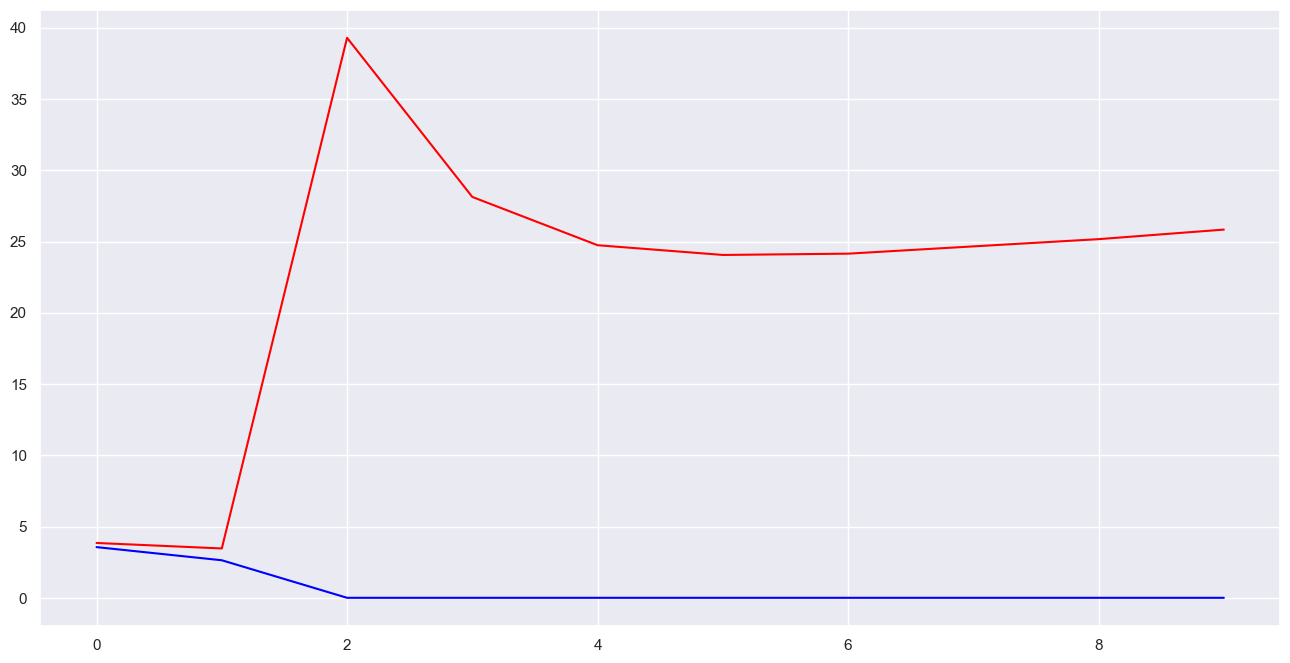

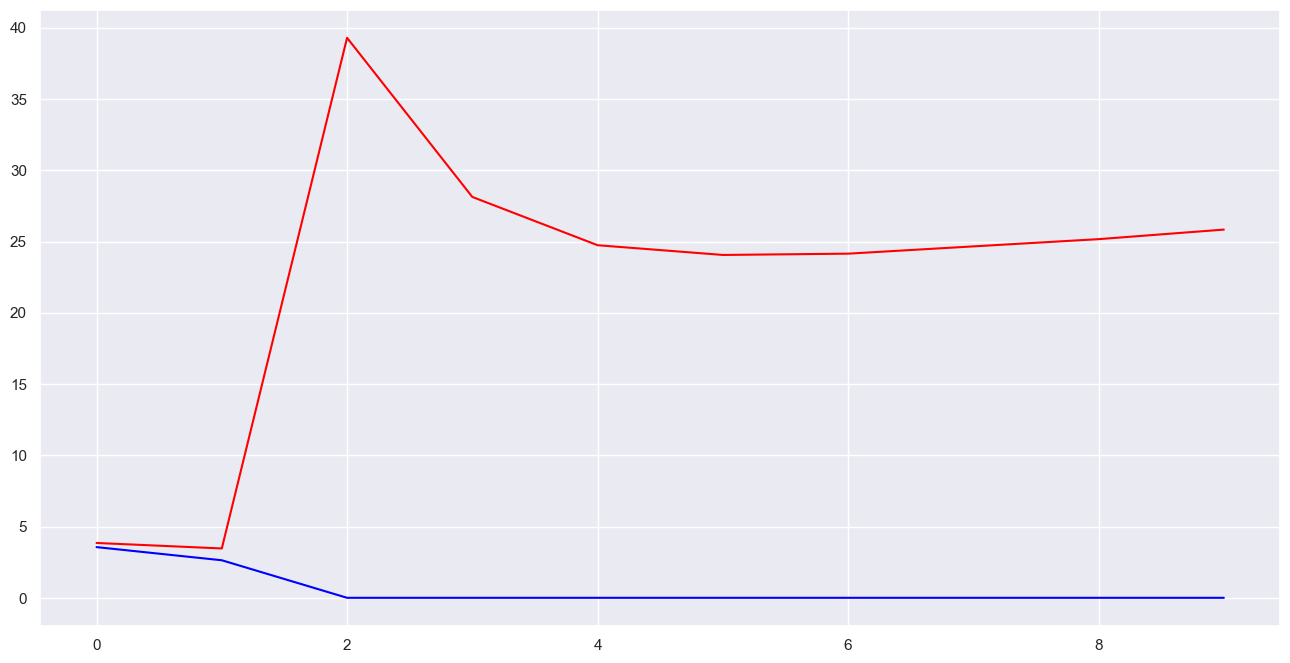

In [7]:
plt.figure(figsize=(16,8))
plt.plot(test_MSE, color="red")
plt.plot(train_MSE, color="blue")

plt.show()

#### Question 4: Now train a lasso regression model. Use 0.1 as the value for alpha. What MSE do you get?

In [28]:
lasso = Lasso(alpha=3)
lasso.fit(X_train, y_train)

y_pred_ls = lasso.predict(X_test)

print("LASSO Regression R2 Score:", r2_score(y_test, y_pred_ls))
print("LASSO Regression MSE:", mean_squared_error(y_test, y_pred_ls))

LASSO Regression R2 Score: 0.04696560200532407
LASSO Regression MSE: 3.6669267295623555


## 10.4 Model Evaluation

#### Question 5 Figure out a better value of alpha to use. First do so by plotting the effect of alpha on the current train-test split, then calculate an overal value using cross validation. Calculate the MSE for both 'best' values.

In [23]:
R2array = []
MSEarray = []
i_array = []

for i in range(1, 101):
    lasso = Lasso(alpha=i/10)
    lasso.fit(X_train, y_train)

    y_pred_ls = lasso.predict(X_test)

    R2 = r2_score(y_test, y_pred_ls)
    MSE = mean_squared_error(y_test, y_pred_ls)

    R2array.append(R2)
    MSEarray.append(MSE)

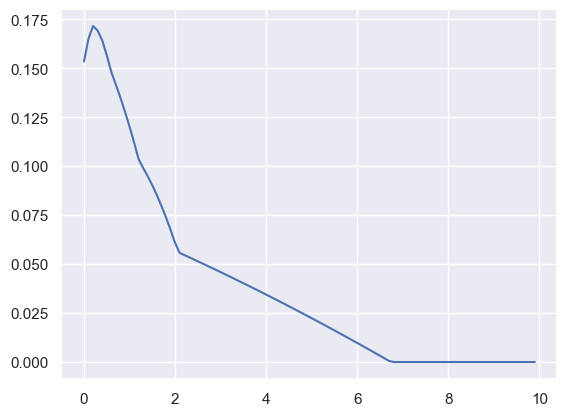

In [24]:
x = np.arange(0, 10, 0.1)

plt.plot(x, R2array)
plt.show()

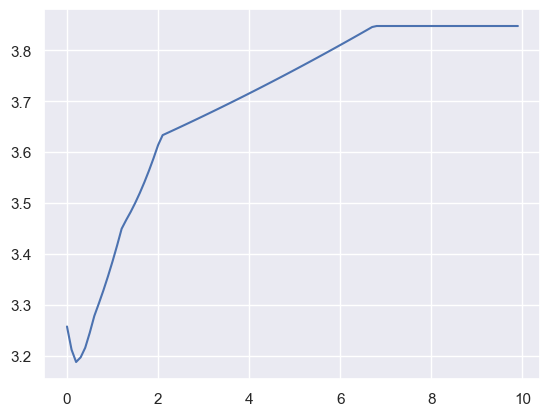

In [25]:
x = np.arange(0, 10, 0.1)

plt.plot(x, MSEarray)
plt.show()

In [26]:
alpha_grid = {'alpha': np.logspace(-3, 1, 50)}

lasso_cv = GridSearchCV(Lasso(), param_grid=alpha_grid, cv=5, scoring='neg_mean_squared_error')
lasso_cv.fit(X_train, y_train)

print("Best Alpha from CV:", lasso_cv.best_params_['alpha'])

Best Alpha from CV: 3.2374575428176433


## 10.5 Exercises

#### Question 1: See section 10.3
#### Question 2: See section 10.3
#### Question 3: See section 10.3
#### Question 4: See section 10.3
#### Question 5: See section 10.4
#### Question 6: Lasso regression can also be used for feature selecting. You can do so by looking at which collumns have been assigned which coefficient. Look at your 'best' trained model (using GSCV) and show the coefficients of each feature and which are dropped in your model. Look back at the features you identified in question 2, how good/bad was your prediction?

In [29]:
for i in range(0, 100):
    try:
        print(lasso.coef_[i])
    except:
        break

-0.00417950280311025
0.0
-0.0
0.0
0.0
0.0
0.0
0.0
-0.0
0.0
0.0
0.0


In [30]:
rdf.head()

,case,site,sex,age,hdlngth,skullw,totlngth,taill,footlgth,earconch,eye,chest,belly
0,1,1,1,8.0,94.1,60.4,89.0,36.0,74.5,54.5,15.2,28.0,36.0
1,2,1,0,6.0,92.5,57.6,91.5,36.5,72.5,51.2,16.0,28.5,33.0
2,3,1,0,6.0,94.0,60.0,95.5,39.0,75.4,51.9,15.5,30.0,34.0
3,4,1,0,6.0,93.2,57.1,92.0,38.0,76.1,52.2,15.2,28.0,34.0
4,5,1,0,2.0,91.5,56.3,85.5,36.0,71.0,53.2,15.1,28.5,33.0


#### Question 7: Lasso regression isn't only useful when working with regression problems. Let's have a look at the feature selection properties of lasso regression in classification. Load in the 'Diabetes' dataset from the logistic regression chapter, create a logistic regression model and calculate the accuracy.

In [103]:
import pandas as pd
import matplotlib.pyplot as plt
import imblearn

import seaborn as sns
from sklearn import metrics
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report
from sklearn.metrics import accuracy_score
from sklearn.metrics import accuracy_score
from imblearn.metrics import specificity_score
from sklearn.metrics import recall_score
from sklearn.metrics import precision_score
from sklearn.metrics import f1_score

df = pd.read_csv("Diabetes.csv")

data = df[["Pregnancies"	,"Glucose"	,"BloodPressure"	,"SkinThickness",	"Insulin",	"BMI",	"DiabetesPedigreeFunction",	"Age"]]
booldata = df["Outcome"]

X_train, X_test, y_train, y_test = train_test_split(data, booldata, test_size=0.3, random_state=101)

GlucoseModel = LogisticRegression(max_iter=10000)
GlucoseModel.fit(X_train, y_train)

ypred = GlucoseModel.predict(X_test)

print(accuracy_score(y_test, ypred))

0.7835497835497836


#### Question 8: Now that we have a standard to compare to, use lasso regression on the dataset to select only the valuable features. Drop them from the dataset and create a new model. Has your accuracy imporved?

In [117]:
LLasso = Lasso(alpha=1)
LLasso.fit(X_train, y_train)

y_pred_ls = LLasso.predict(X_test)

print("LASSO Regression R2 Score:", r2_score(y_test, y_pred_ls))
print("LASSO Regression MSE:", mean_squared_error(y_test, y_pred_ls))

LASSO Regression R2 Score: 0.23870962129189888
LASSO Regression MSE: 0.1733415434737623


In [118]:
R2array = []
MSEarray = []
i_array = []

for i in range(1, 201):
    lasso = Lasso(alpha=i/10)
    lasso.fit(X_train, y_train)

    y_pred_ls = lasso.predict(X_test)

    R2 = r2_score(y_test, y_pred_ls)
    MSE = mean_squared_error(y_test, y_pred_ls)

    R2array.append(R2)
    MSEarray.append(MSE)

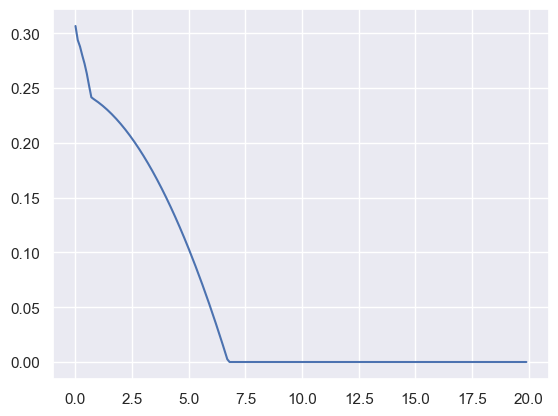

In [119]:
x = np.arange(0, 20, 0.1)

plt.plot(x, R2array)
plt.show()

In [120]:
for i in range(0, 100):
    try:
        print(LLasso.coef_[i])
    except:
        break

0.0
0.0057834519981884115
0.0
0.0
0.0
0.0
0.0
0.0
